<a href="https://colab.research.google.com/github/youssefouabir-lab/Introduction_to_ai/blob/main/Lesson_5_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Lesson 5 assignment**



In [ ]:
# Titanic Dataset Exploratory Data Analysis

# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# keep the plots clean and consistent
sns.set_theme(style="whitegrid")

## Task 1: Load the Titanic dataset

In [ ]:
# the csv has to sit in the same folder as the notebook
file_path = "Titanic-Dataset.csv"
df = pd.read_csv(file_path)

# quick check that it loaded properly
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (891, 12)


**Notes – Task 1:** The dataset loaded correctly with **891 passengers (rows)** and **12 columns**. The CSV file has to be in the same folder as the notebook

## Task 2: Inspect the data

In [ ]:
# first 5 rows
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
#last 5 rows
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [ ]:
# data types of each column
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
# summary statistics of the numerical columns
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# how many missing values per column
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


**Notes for the task2:**
- `head()` and `tail()` show the data is one row per passenger, with a mix of numbers (`Age`, `Fare`, `SibSp`, `Parch`) and text (`Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`).
- `dtypes` confirms `Survived` and `Pclass` are stored as integers even though they are really categories (0/1 and 1/2/3), so I handle them as categories when needed.
- `describe()`: only **38.4%** of passengers survived (mean of `Survived`). The average age is about **29.7** (range 0.42 to 80). `Fare` is very skewed: the mean is **32.20** but the median is only **14.45**, and the max is **512.33**, so a few very expensive tickets pull the average up.
- Missing values: `Age` has **177** missing (about 20%), `Cabin` has **687** missing (about 77%) and `Embarked` has 2 missing. These need attention in the next step.

## Task 3: Clean and preprocess the data

In [ ]:
#new categorical feature 'PclassCategory' from 'Pclass'
df['PclassCategory'] = df['Pclass'].map({1: 'First Class', 2: 'Second Class', 3: 'Third Class'})
df['PclassCategory'] = pd.Categorical(
    df['PclassCategory'],
    categories=['First Class', 'Second Class', 'Third Class'],
    ordered=True
)

df[['Pclass', 'PclassCategory']].head()

,Pclass,PclassCategory
0,3,Third Class
1,1,First Class
2,3,Third Class
3,1,First Class
4,3,Third Class


In [ ]:
#new categorical feature 'CabinCategory' from 'Cabin'
# the deck is the first letter of the cabin number (A, B, C...), missing cabins become 'Unknown'
df['CabinCategory'] = df['Cabin'].str[0].fillna('Unknown')

print(df['CabinCategory'].value_counts())
df[['Cabin', 'CabinCategory']].head(10)

CabinCategory
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64


,Cabin,CabinCategory
0,NaN,Unknown
1,C85,C
2,NaN,Unknown
3,C123,C
4,NaN,Unknown
5,NaN,Unknown
6,E46,E
7,NaN,Unknown
8,NaN,Unknown
9,NaN,Unknown


In [ ]:
#handle missing values in 'Age'
# first check how many are missing
print("Missing ages before:", df['Age'].isnull().sum())

# fill with the mean age
mean_age = df['Age'].mean()
df['Age'] = df['Age'].fillna(mean_age)

print("Mean age used:", round(mean_age, 2))
print("Missing ages after:", df['Age'].isnull().sum())

Missing ages before: 177
Mean age used: 29.7
Missing ages after: 0


In [ ]:
#'Family' feature = siblings/spouses + parents/children aboard
df['Family'] = df['SibSp'] + df['Parch']

df[['SibSp', 'Parch', 'Family']].head()

,SibSp,Parch,Family
0,1,0,1
1,1,0,1
2,0,0,0
3,1,0,1
4,0,0,0


**Notes for the task 3:**
- **PclassCategory:** turned the numbers 1/2/3 into First/Second/Third Class labels (ordered) so plots and tables are easier to read.
- **CabinCategory:** I used the first letter of the cabin as the deck. Since 687 passengers have no cabin, they are labelled `Unknown`. Decks with the most known cabins are C (59), B (47), D (33) and E (32), while T has only 1 passenger. Missing cabins are mostly lower-class passengers, so `Unknown` is informative on its own and not just a gap.
- **Age:** 177 missing values were filled with the mean age (**29.7**). This is simple and keeps all 891 rows, but it has a side effect: it adds a spike at 29.7 and lowers the standard deviation (14.5 to 13.0). I keep this in mind when reading the age plots below.
- **Family:** `SibSp + Parch` = relatives travelling with the passenger. A value of 0 means the person travelled alone (the passenger themself is not counted).

## Task 4: Identify specific data points

In [ ]:
#passengers with the highest fare
# using == max so we catch ties too
highest_fare_passengers = df[df['Fare'] == df['Fare'].max()]
highest_fare_passengers[['PassengerId', 'Name', 'Pclass', 'Sex', 'Age', 'Fare', 'Cabin', 'Embarked']]

,PassengerId,Name,Pclass,Sex,Age,Fare,Cabin,Embarked
258,259,"Ward, Miss. Anna",1,female,35.0,512.3292,NaN,C
679,680,"Cardeza, Mr. Thomas Drake Martinez",1,male,36.0,512.3292,B51 B53 B55,C
737,738,"Lesurer, Mr. Gustave J",1,male,35.0,512.3292,B101,C


In [ ]:
#passengers with the largest family size
largest_family_passengers = df[df['Family'] == df['Family'].max()]
largest_family_passengers[['PassengerId', 'Name', 'Pclass', 'SibSp', 'Parch', 'Family', 'Survived']]

,PassengerId,Name,Pclass,SibSp,Parch,Family,Survived
159,160,"Sage, Master. Thomas Henry",3,8,2,10,0
180,181,"Sage, Miss. Constance Gladys",3,8,2,10,0
201,202,"Sage, Mr. Frederick",3,8,2,10,0
324,325,"Sage, Mr. George John Jr",3,8,2,10,0
792,793,"Sage, Miss. Stella Anna",3,8,2,10,0
846,847,"Sage, Mr. Douglas Bullen",3,8,2,10,0
863,864,"Sage, Miss. Dorothy Edith ""Dolly""",3,8,2,10,0


**Note for Task 4:**
- **Highest fare:** three passengers tie at **512.33** (Anna Ward, Thomas Cardeza and Gustave Lesurer). All three are First Class and boarded at Cherbourg (C). This is a big outlier compared to the median fare of 14.45.
- **Largest family:** **7 passengers from the Sage family** have `Family = 10` (8 siblings/spouses + 2 parents/children). They were all in Third Class and **none of them survived**.

## Task 5: Demonstrate Pandas Series and DataFrame functionalities

In [ ]:
#Series of passenger names
names_series = df['Name']

print(type(names_series))
names_series.head()

<class 'pandas.core.series.Series'>


,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"


In [ ]:
# manipulating the Series: upper case, length of each name
print(names_series.str.upper().head(3))
print()
print(names_series.str.len().head(3))

0                              BRAUND, MR. OWEN HARRIS
1    CUMINGS, MRS. JOHN BRADLEY (FLORENCE BRIGGS TH...
2                               HEIKKINEN, MISS. LAINA
Name: Name, dtype: object

0    23
1    51
2    22
Name: Name, dtype: int64


In [ ]:
#DataFrame of passenger names and ages
names_ages_df = df[['Name', 'Age']]

print(type(names_ages_df))
names_ages_df.head()

<class 'pandas.core.frame.DataFrame'>


,Name,Age
0,"Braund, Mr. Owen Harris",22.0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0
2,"Heikkinen, Miss. Laina",26.0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0
4,"Allen, Mr. William Henry",35.0


In [ ]:
#slice the DataFrame to show only passengers older than 50
older_passengers = names_ages_df[names_ages_df['Age'] > 50]

print("Passengers older than 50:", len(older_passengers))
older_passengers.head(10)

Passengers older than 50: 64


,Name,Age
6,"McCarthy, Mr. Timothy J",54.0
11,"Bonnell, Miss. Elizabeth",58.0
15,"Hewlett, Mrs. (Mary D Kingcome)",55.0
33,"Wheadon, Mr. Edward H",66.0
54,"Ostby, Mr. Engelhart Cornelius",65.0
94,"Coxon, Mr. Daniel",59.0
96,"Goldschmidt, Mr. George B",71.0
116,"Connors, Mr. Patrick",70.5
124,"White, Mr. Percival Wayland",54.0
150,"Bateman, Rev. Robert James",51.0


In [ ]:
# indexing and slicing operations
# by position with iloc (first 5 rows, first 2 columns)
print(names_ages_df.iloc[0:5, 0:2])
print()

# by label with loc (rows 0 to 4, 'Name' column only)
print(names_ages_df.loc[0:4, 'Name'])
print()

# using the name as the index, then looking up one passenger
names_indexed = names_ages_df.set_index('Name')
print(names_indexed.loc['Braund, Mr. Owen Harris'])

                                                Name   Age
0                            Braund, Mr. Owen Harris  22.0
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0
2                             Heikkinen, Miss. Laina  26.0
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0
4                           Allen, Mr. William Henry  35.0

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
Name: Name, dtype: object

Age    22.0
Name: Braund, Mr. Owen Harris, dtype: float64


**Note for Task 5:** `df['Name']` is a **Series** (one column with an index) and `df[['Name', 'Age']]` is a **DataFrame** (a table). Filtering with `Age > 50` returns **64 passengers**. I also showed `iloc` (selection by position), `loc` (selection by label) and `set_index('Name')` to look up a single passenger by name.

## Task 6: Multi-indexing

In [ ]:
#multi-index DataFrame of survival rates by Sex and Pclass
multi_index_df = df.groupby(['Sex', 'Pclass'])['Survived'].mean().to_frame(name='SurvivalRate')

print(multi_index_df.index)
multi_index_df

MultiIndex([('female', 1),
            ('female', 2),
            ('female', 3),
            (  'male', 1),
            (  'male', 2),
            (  'male', 3)],
           names=['Sex', 'Pclass'])


SurvivalRate
Sex    Pclass              
female 1           0.968085
       2           0.921053
       3           0.500000
male   1           0.368852
       2           0.157407
       3           0.135447

In [ ]:
# indexing into the multi-index
# all rows for females
print(multi_index_df.loc['female'])
print()

# one specific group: first class males
print(multi_index_df.loc[('male', 1)])
print()

# cross-section: third class for both sexes
print(multi_index_df.xs(3, level='Pclass'))

        SurvivalRate
Pclass              
1           0.968085
2           0.921053
3           0.500000

SurvivalRate    0.368852
Name: (male, 1), dtype: float64

        SurvivalRate
Sex                 
female      0.500000
male        0.135447


**Notes for Task 6 (multi-index survival rates):** grouping by `Sex` and `Pclass` creates a two-level index, which makes it easy to pull out groups with `.loc` and `.xs`.

| Sex | 1st class | 2nd class | 3rd class |
|---|---|---|---|
| Female | 96.8% | 92.1% | 50.0% |
| Male | 36.9% | 15.7% | 13.5% |

Women survived far more than men in every class. Class also matters: first and second class women were almost all saved, but third class women only had a 50% rate. For men, only first class had a decent chance.

## Task 7: Visualizations

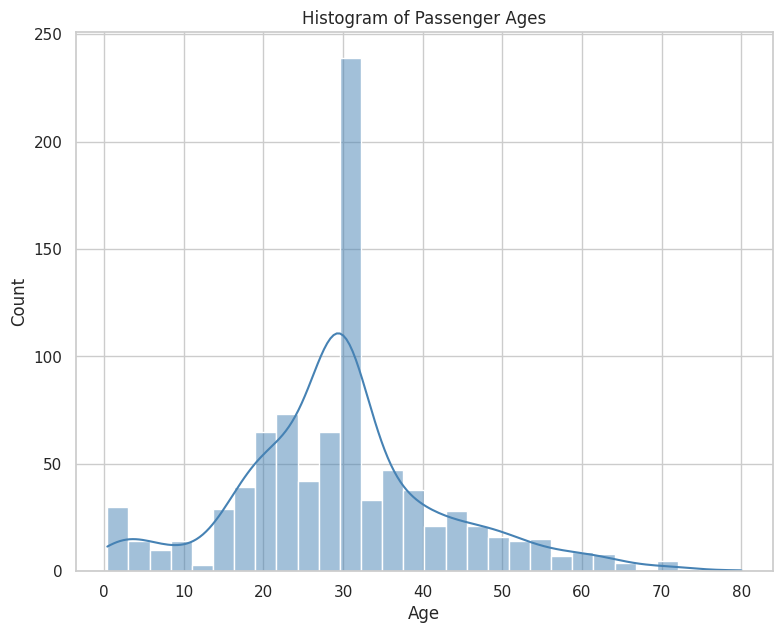

In [ ]:
#histogram of passenger ages
plt.figure(figsize=(9, 7))
sns.histplot(df['Age'], bins=30, kde=True, color='steelblue')
plt.title('Histogram of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

**Notes – Histogram:** most passengers are between about 20 and 40 years old. There is a small group of very young children (babies and toddlers) and a long tail up to 80. The tall bar near 30 is mostly caused by filling the 177 missing ages with the mean (29.7), so it's an artifact of the cleaning step and not a real peak.

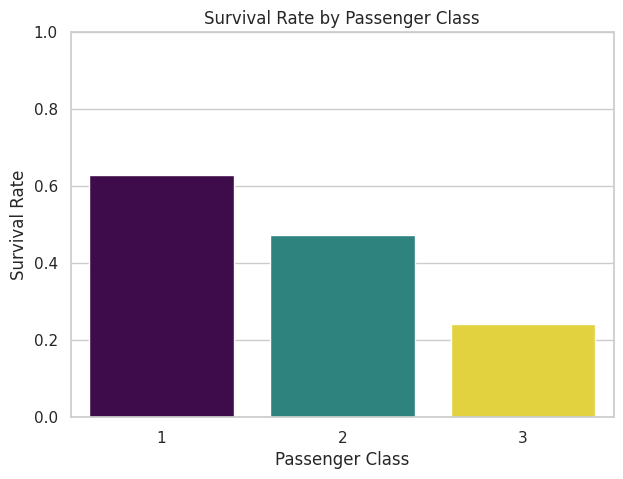

In [ ]:
#bar plot of survival rates by passenger class
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x='Pclass', y='Survived', hue='Pclass', errorbar=None, palette='viridis', legend=False)
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)
plt.show()

**Notes – Survival by class:** survival drops clearly as the class goes down: about **63%** in First Class, **47%** in Second and **24%** in Third. Passengers with better tickets had a much better chance of surviving.

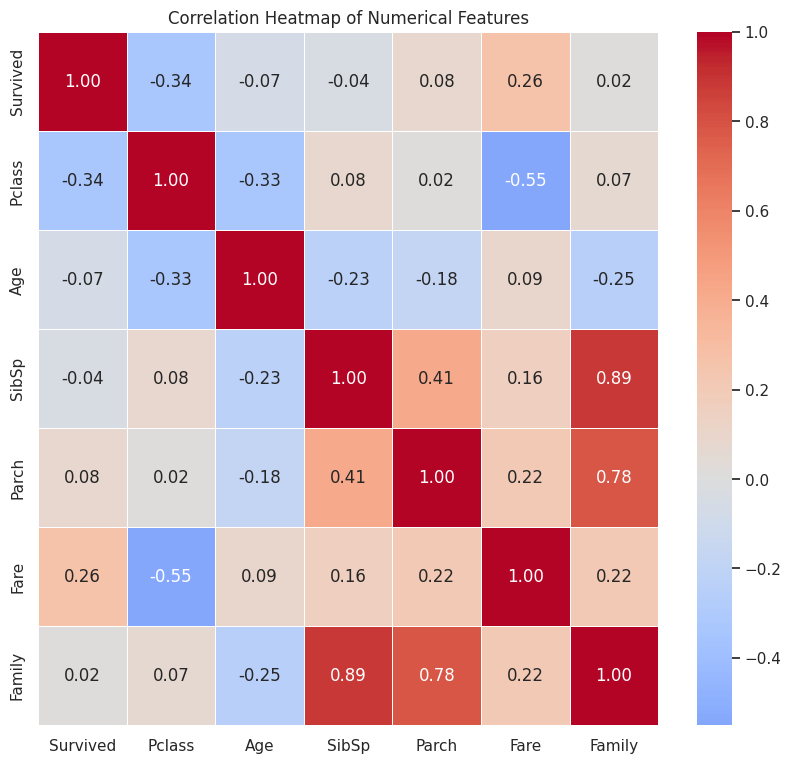

In [ ]:
#heatmap of correlation between numerical features
# PassengerId is just an ID so I leave it out
numeric_df = df.select_dtypes(include='number').drop(columns=['PassengerId'])

plt.figure(figsize=(10, 9))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

**Notes – Correlation heatmap:**
- `Pclass` and `Fare` have the strongest correlation (**-0.55**): higher class number (cheaper class) means a lower fare, which makes sense.
- `Survived` is negatively correlated with `Pclass` (**-0.34**) and positively with `Fare` (**0.26**), so richer, higher-class passengers survived more often.
- `Pclass` and `Age` (**-0.33**): first class passengers tended to be older.
- `SibSp` and `Parch` are moderately related (**0.41**). `Family` is very correlated with both (**0.89** and **0.78**), but that is expected because it is built from them.
- `Age` has almost no linear relationship with `Survived` (**-0.07**).
- Correlation only measures linear relationships between numbers, so `Sex` (text) is not in here even though it is one of the strongest predictors (see Task 8).

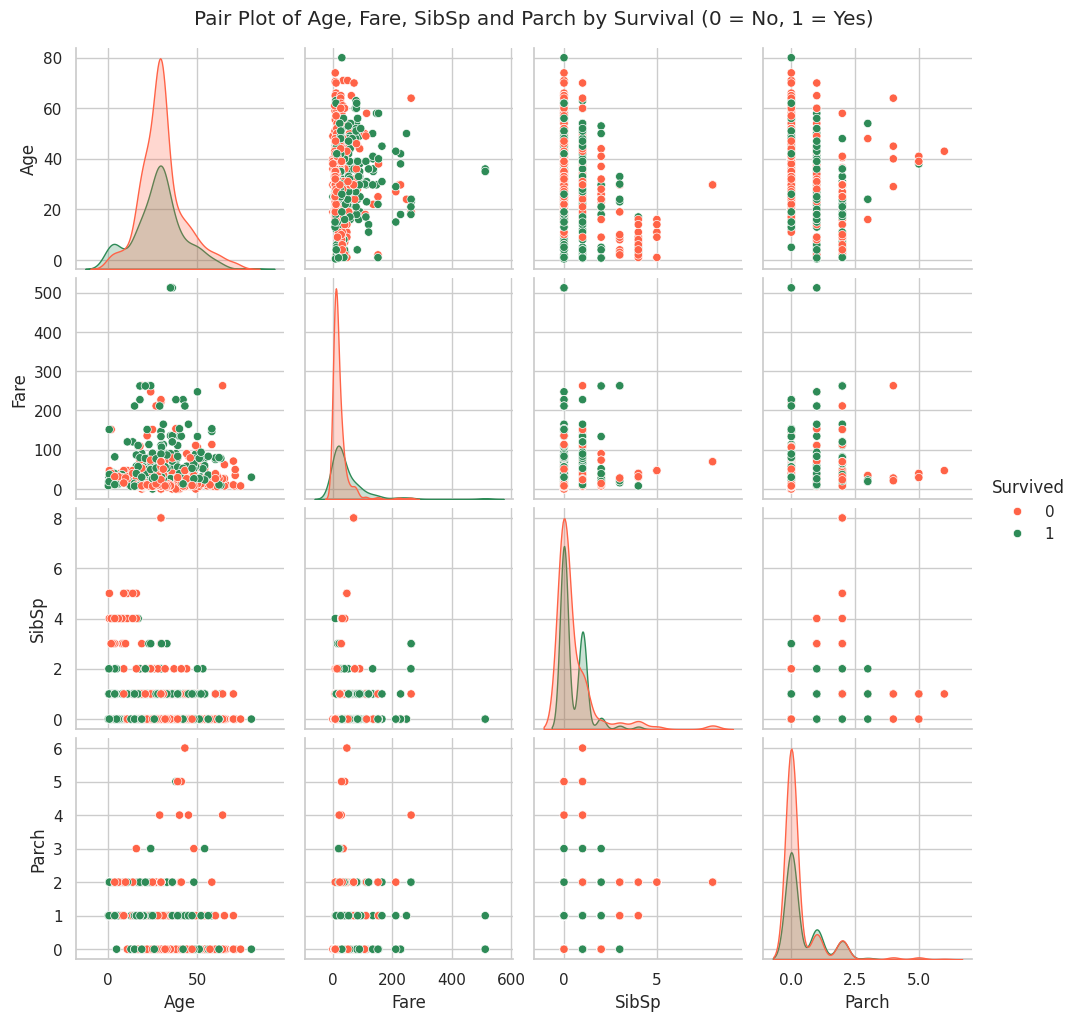

In [ ]:
#pair plot of Age, Fare, SibSp and Parch, colored by Survived
sns.pairplot(
    df[['Age', 'Fare', 'SibSp', 'Parch', 'Survived']],
    hue='Survived',
    palette={0: 'tomato', 1: 'seagreen'},
    corner=False
)
plt.suptitle('Pair Plot of Age, Fare, SibSp and Parch by Survival (0 = No, 1 = Yes)', y=1.02)
plt.show()

**Notes – Pair plot:**
- Passengers who paid higher fares (green) survived more often. Among passengers with a fare over 100, about 74% survived.
- `Fare` is heavily right skewed: most points are bunched at low fares with a few extreme values.
- Passengers with many siblings/spouses (`SibSp` of 5 or more) did not survive (0 out of 12), which matches the large Sage family from Task 4.
- Very young children (under 5) had a high survival rate (about 68%).
- The vertical band at Age ≈ 30 comes from the mean imputation.

## Task 8: Analyze survival rates

In [ ]:
#survival rate by sex
survival_by_sex = df.groupby('Sex')['Survived'].mean()

print((survival_by_sex * 100).round(2))

Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


In [ ]:
#survival rate by passenger class
survival_by_class = df.groupby('Pclass')['Survived'].mean()

print((survival_by_class * 100).round(2))

Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


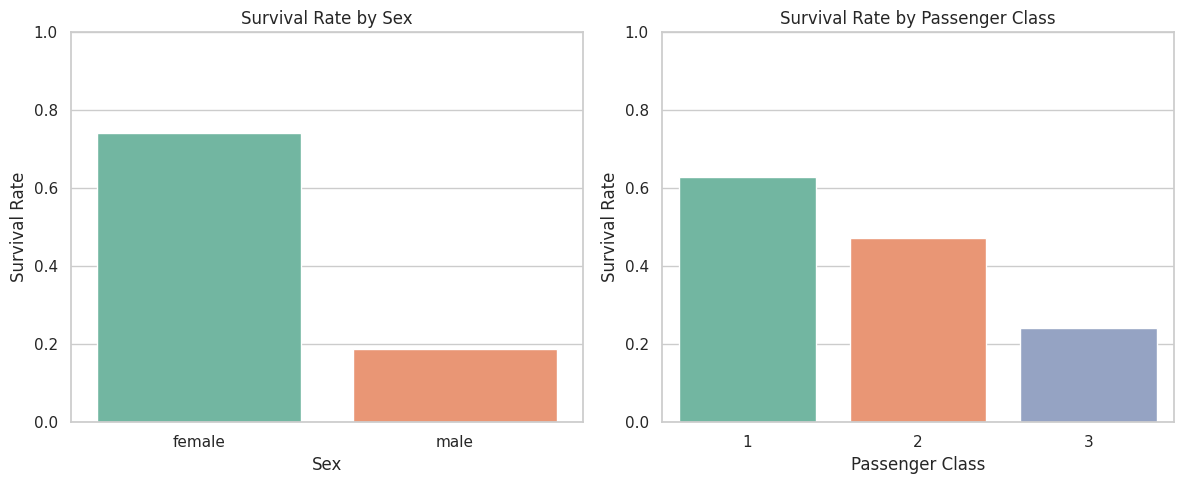

In [ ]:
#quick chart so the rates are easier to compare
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x=survival_by_sex.index, y=survival_by_sex.values, hue=survival_by_sex.index,
            palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Survival Rate by Sex')
axes[0].set_xlabel('Sex')
axes[0].set_ylabel('Survival Rate')
axes[0].set_ylim(0, 1)

sns.barplot(x=survival_by_class.index, y=survival_by_class.values, hue=survival_by_class.index,
            palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Survival Rate by Passenger Class')
axes[1].set_xlabel('Passenger Class')
axes[1].set_ylabel('Survival Rate')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Notes – Survival rates:**
- **By sex:** **74.2%** of women survived compared to only **18.9%** of men. This is the biggest gap in the dataset and fits the "women and children first" rule for the lifeboats.
- **By class:** First Class **63.0%**, Second Class **47.3%**, Third Class **24.2%**. Social class clearly affected survival, probably due to cabin location, access to the lifeboats and priority during the evacuation.
- Together with the multi-index table from Task 6, sex and class combine: a first class woman (96.8%) had a much better chance than a third class man (13.5%).

## Task 9: Analyze age distribution

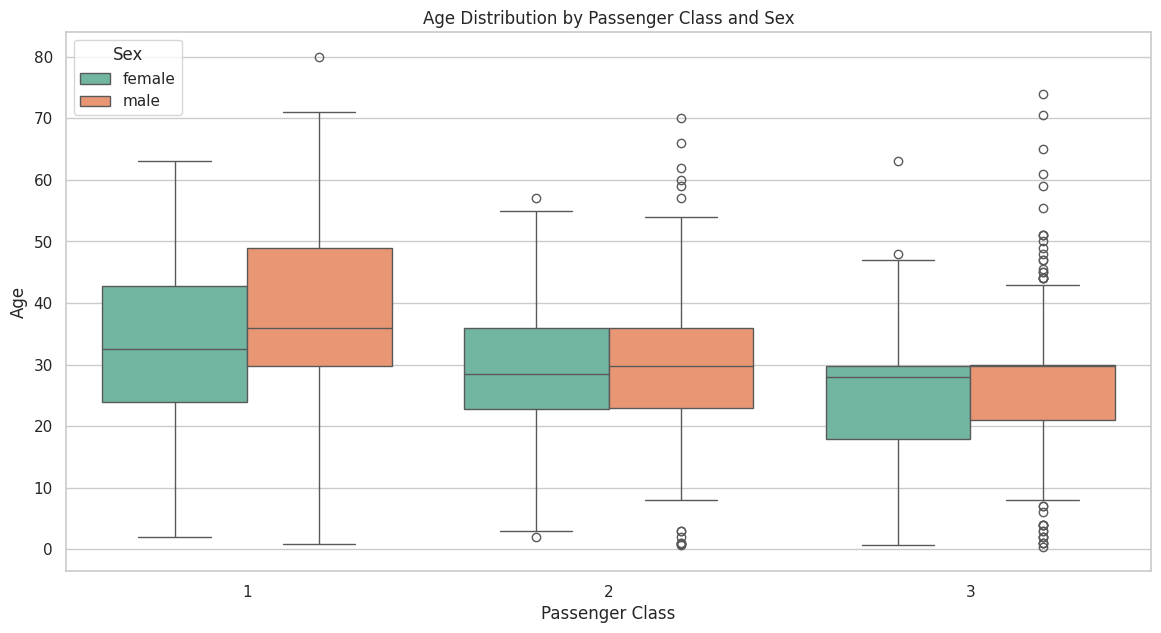

In [ ]:
#box plot of age distribution by passenger class and sex
plt.figure(figsize=(14, 7))
sns.boxplot(data=df, x='Pclass', y='Age', hue='Sex', palette='Set2')
plt.title('Age Distribution by Passenger Class and Sex')
plt.xlabel('Passenger Class')
plt.ylabel('Age')
plt.show()

In [ ]:
# median age per group to back up the box plot
df.groupby(['Pclass', 'Sex'])['Age'].median().round(1)

Pclass  Sex   
1       female    32.5
        male      36.0
2       female    28.5
        male      29.7
3       female    28.0
        male      29.7
Name: Age, dtype: float64

**Notes – Age distribution by class and sex:**
- Passengers get **older as the class goes up**: the median age is **32.5 (women) and 36.0 (men)** in First Class, about **28.5 / 29.7** in Second Class and **28.0 / 29.7** in Third Class.
- First Class has the widest spread and Third Class is the youngest, with many young adults and children.
- Each class has some older outliers (dots above the whiskers).
- The median of 29.7 for men in Second and Third Class is exactly the mean we used to fill missing ages, which shows how many missing values were in those groups. So these medians are slightly pulled toward the mean by the imputation.

## Task 10: Analyze fare distribution

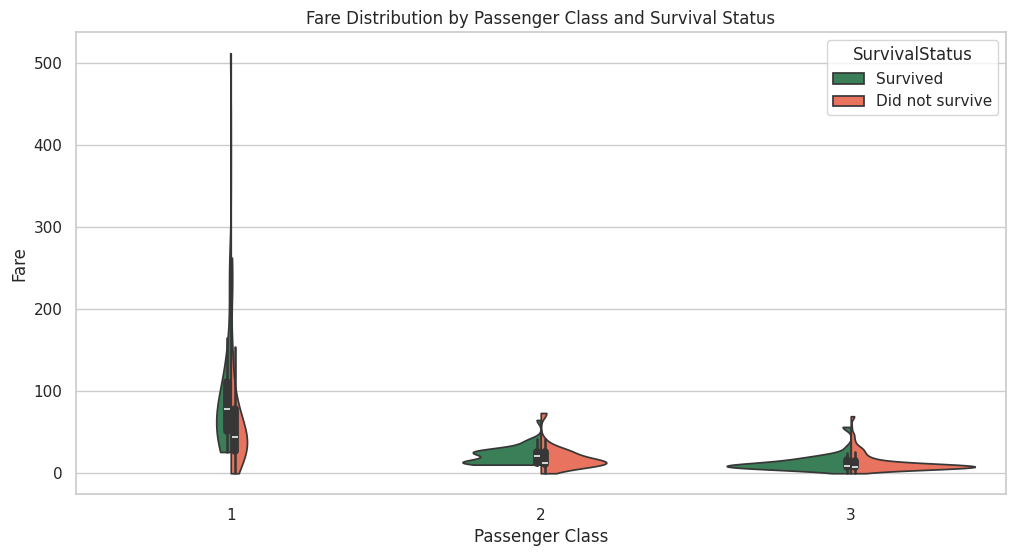

In [ ]:
#violin plot of fare distribution by passenger class and survival status
# readable labels for the legend instead of 0/1
df['SurvivalStatus'] = df['Survived'].map({0: 'Did not survive', 1: 'Survived'})

plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='Pclass', y='Fare', hue='SurvivalStatus', split=True, cut=0,
               palette={'Did not survive': 'tomato', 'Survived': 'seagreen'})
plt.title('Fare Distribution by Passenger Class and Survival Status')
plt.xlabel('Passenger Class')
plt.ylabel('Fare')
plt.show()

In [ ]:
# median fare per group to back up the violin plot
df.groupby(['Pclass', 'SurvivalStatus'])['Fare'].median().round(2)

Pclass  SurvivalStatus 
1       Did not survive    44.75
        Survived           77.96
2       Did not survive    13.00
        Survived           21.00
3       Did not survive     8.05
        Survived            8.52
Name: Fare, dtype: float64

**Notes – Fare distribution by class and survival:**
- Fares are very different between classes: median fare is about **60.29** in First Class, **14.25** in Second and **8.05** in Third.
- Within each class, survivors paid a bit more than non-survivors (median **77.96 vs 44.75** in First Class, **21.00 vs 13.00** in Second, **8.52 vs 8.05** in Third). The difference is big in First Class and almost nothing in Third Class.
- First Class has a very long tail (fares up to 512), so its violin is stretched, while Second and Third are packed at low fares.
- The dataset also has 15 passengers with a fare of 0, which could be missing data or free tickets.

## Overall EDA Insights

**Key insights from the EDA:**

1. **Overall survival was low:** only 38.4% of the 891 passengers survived.
2. **Sex was the strongest factor:** 74.2% of women survived vs 18.9% of men.
3. **Class mattered a lot:** survival went from 63.0% (First) to 47.3% (Second) to 24.2% (Third). Sex and class together are even more telling, from 96.8% for first class women to 13.5% for third class men.
4. **Fare and class go together:** a higher fare means a better class (correlation -0.55 with `Pclass`) and a higher chance of survival (0.26 with `Survived`).
5. **Large families did badly:** the largest family (the Sage family, 7 passengers with `Family = 10`) all died, and passengers with a lot of siblings/spouses aboard survived rarely. Small families (1 to 3 relatives) did better than people travelling alone.
6. **Children had better odds:** passengers under 5 survived about 68% of the time.

**Data quality notes and limitations:**
- `Age` had 177 missing values filled with the mean. This keeps every row but creates an artificial spike at 29.7 and slightly shrinks the age differences between groups. Filling with the median by class and sex would be a better option for a deeper analysis.
- `Cabin` is missing for about 77% of passengers, so `CabinCategory` is mostly `Unknown`. `Embarked` has 2 missing values that were not needed for this assignment.
- `Fare` is heavily skewed with a few extreme values, so the median is a better summary than the mean.
- These are patterns in the data and don't prove cause and effect.

In [ ]:
print("EDA tasks completed.")

EDA tasks completed.
